In [14]:
from __future__ import annotations
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kde_tools.bandwidths import (
    bandwidth_grid_linear_in_psi_beta,
    gaussian_mise_oracle_bandwidth,
)
from kde_tools.density import (
    exact_gaussian_kde_l2_gram,
    exact_oracle_ise_values,
    gaussian_kde_values,
)
from kde_tools.experiments import beta2_bandwidth_selection_counts
from kde_tools.fourier import (
    beta2_divergence_matrix_fft,
    beta2_similarity_matrix_fft,
    kde_family_fft,
)
from kde_tools.gaussian_mixtures import exact_mixture_mise_values
import kde_tools.plotting_functions as kde_plotting_functions
importlib.reload(kde_plotting_functions)
from kde_tools.plotting_functions import (
    plot_bandwidth_distributions,
    plot_perron_vector,
)
from kde_tools.quadrature import (
    compute_quadrature_similarity_matrices,
    quadrature_beta2_divergence_matrix,
    quadrature_grid_for_kdes,
    quadrature_similarity_matrices,
    select_quadrature_similarity_bandwidths,
)
from kde_tools.similarities import (
    beta2_divergence_matrix,
    beta2_similarity_matrix,
    perron_vector,
    select_spectral_bandwidth,
    spectral_choice_from_similarity,
    squared_l2_distance_from_gram,
)

In [15]:
def print_matrix(M):
    print(pd.DataFrame(D2).to_string(index=False, header=False, float_format=lambda x: f"{x:.4f}"))

In [16]:
rng = np.random.default_rng(12345)
n = 200
N = 200
tau = 1.0
samples = rng.normal(loc=0.0, scale=1.0, size=n)
h_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=0.1,
    h_max=1.0,
    beta=2.0,
    grid_size=N,
)
# print(h_grid)
D2 = beta2_divergence_matrix(samples=samples, h_grid=h_grid)
SimMatr = beta2_similarity_matrix(samples=samples, h_grid=h_grid, tau=tau)
# print()
# print_matrix(D2)
# print()
# print_matrix(SimMatr)

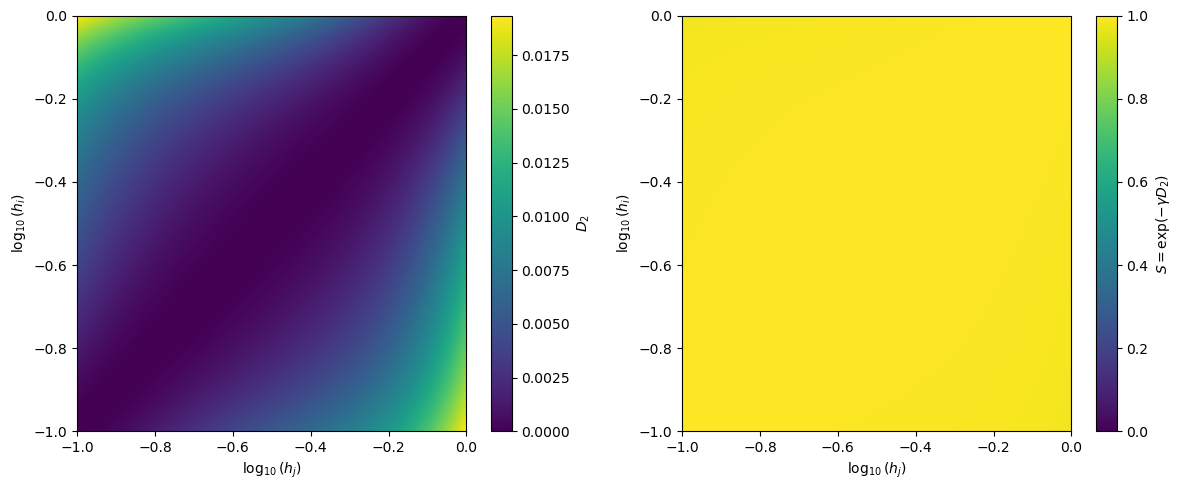

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

extent = [
    np.log10(h_grid[0]),
    np.log10(h_grid[-1]),
    np.log10(h_grid[0]),
    np.log10(h_grid[-1]),
]

image_d2 = axes[0].imshow(
    D2,
    origin="lower",
    aspect="auto",
    extent=extent,
    cmap="viridis",
)
axes[0].set_xlabel(r"$\log_{10}(h_j)$")
axes[0].set_ylabel(r"$\log_{10}(h_i)$")
colorbar_d2 = fig.colorbar(image_d2, ax=axes[0])
colorbar_d2.set_label(r"$D_2$")

image_similarity = axes[1].imshow(
    SimMatr,
    origin="lower",
    aspect="auto",
    extent=extent,
    cmap="viridis",
    vmin=0.0,
    vmax=1.0,
)
axes[1].set_xlabel(r"$\log_{10}(h_j)$")
axes[1].set_ylabel(r"$\log_{10}(h_i)$")
colorbar_similarity = fig.colorbar(image_similarity, ax=axes[1])
colorbar_similarity.set_label(r"$S=\exp(-\gamma D_2)$")

plt.tight_layout()
plt.show()

In [18]:
vec = perron_vector(matrix=SimMatr)
print(vec)

[0.00498656 0.00498708 0.00498759 0.0049881  0.00498859 0.00498908
 0.00498956 0.00499003 0.00499049 0.00499095 0.00499139 0.00499183
 0.00499226 0.00499268 0.00499309 0.0049935  0.00499389 0.00499428
 0.00499466 0.00499503 0.0049954  0.00499575 0.0049961  0.00499644
 0.00499677 0.00499709 0.0049974  0.00499771 0.00499801 0.0049983
 0.00499859 0.00499887 0.00499914 0.0049994  0.00499966 0.00499991
 0.00500015 0.00500039 0.00500062 0.00500084 0.00500106 0.00500127
 0.00500148 0.00500168 0.00500187 0.00500206 0.00500225 0.00500243
 0.0050026  0.00500277 0.00500294 0.0050031  0.00500326 0.00500341
 0.00500356 0.0050037  0.00500384 0.00500398 0.00500411 0.00500424
 0.00500437 0.00500449 0.00500461 0.00500473 0.00500484 0.00500495
 0.00500506 0.00500516 0.00500526 0.00500536 0.00500545 0.00500555
 0.00500564 0.00500572 0.00500581 0.00500589 0.00500597 0.00500604
 0.00500612 0.00500619 0.00500626 0.00500632 0.00500638 0.00500645
 0.0050065  0.00500656 0.00500661 0.00500667 0.00500671 0.00500

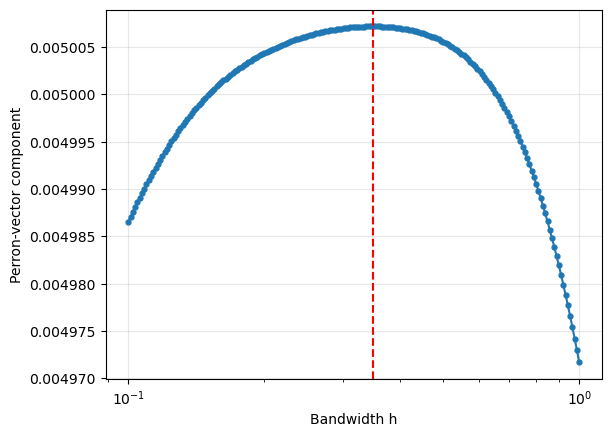

In [19]:
plot_perron_vector(h_grid=h_grid, vector=vec);

Plot the ISE($h$)-curve

In [20]:
ise_values = exact_oracle_ise_values(samples, h_grid, sigma2=1.0)

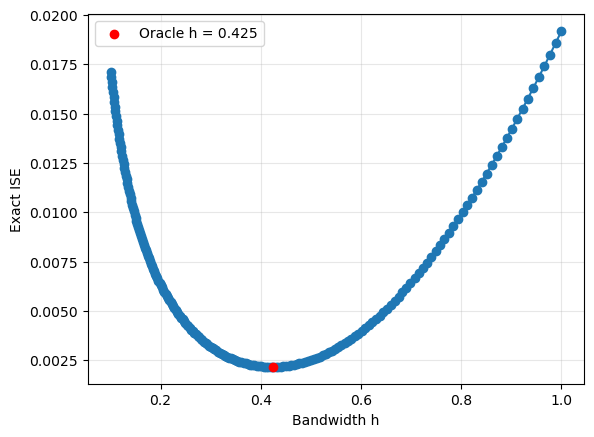

In [21]:
oracle_index = np.argmin(ise_values)

plt.plot(h_grid, ise_values, marker="o")
plt.scatter(
    h_grid[oracle_index],
    ise_values[oracle_index],
    color="red",
    label=f"Oracle h = {h_grid[oracle_index]:.3f}",
    zorder=3,
)
plt.xlabel("Bandwidth h")
plt.ylabel("Exact ISE")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [9]:
choice = spectral_choice_from_similarity(SimMatr)

spectral_index = choice["selected_index"]
spectral_h = h_grid[spectral_index]

ise_values = exact_oracle_ise_values(
    samples=samples,
    h_grid=h_grid,
    sigma2=1.0,
)

oracle_index = int(np.argmin(ise_values))
oracle_h = h_grid[oracle_index]

print(f"Spectral bandwidth: h = {spectral_h:.6f}")
print(f"Oracle bandwidth:   h = {oracle_h:.6f}")
print(f"Spectral ISE:       {ise_values[spectral_index]:.6f}")
print(f"Minimum ISE:        {ise_values[oracle_index]:.6f}")

Spectral bandwidth: h = 0.348910
Oracle bandwidth:   h = 0.424757
Spectral ISE:       0.002508
Minimum ISE:        0.002161


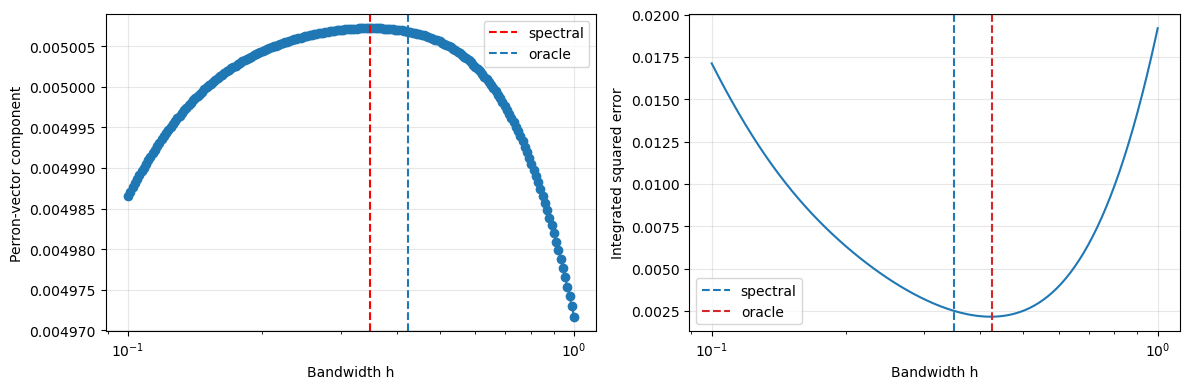

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_perron_vector(
    h_grid=h_grid,
    vector=choice["perron_vector"],
    ax=axes[0],
    maximum_label="spectral",
)
axes[0].axvline(
    oracle_h,
    color="tab:blue",
    linestyle="--",
    label="oracle",
)
axes[0].legend()

axes[1].plot(h_grid, ise_values)
axes[1].axvline(
    spectral_h,
    color="tab:blue",
    linestyle="--",
    label="spectral",
)
axes[1].axvline(
    oracle_h,
    color="tab:red",
    linestyle="--",
    label="oracle",
)
axes[1].set_xscale("log")
axes[1].set_xlabel("Bandwidth h")
axes[1].set_ylabel("Integrated squared error")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
ise_values = exact_oracle_ise_values(
    samples=samples,
    h_grid=h_grid,
    sigma2=1.0,
)

mise_values = exact_mixture_mise_values(
    n=len(samples),
    h_grid=h_grid,
    weights=np.array([1.0]),
    means=np.array([0.0]),
    sigmas=np.array([1.0]),
)

ise_index = int(np.argmin(ise_values))
mise_index = int(np.argmin(mise_values))

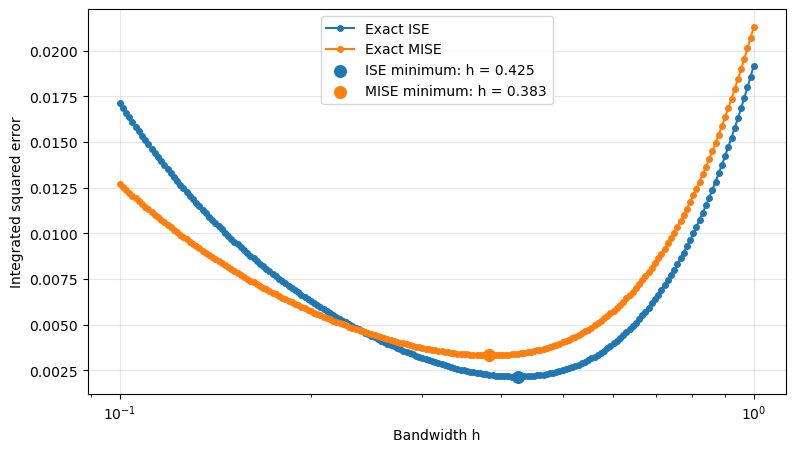

In [12]:
plt.figure(figsize=(9, 5))

plt.plot(
    h_grid,
    ise_values,
    marker="o",
    markersize=4,
    label="Exact ISE",
)

plt.plot(
    h_grid,
    mise_values,
    marker="o",
    markersize=4,
    label="Exact MISE",
)

plt.scatter(
    h_grid[ise_index],
    ise_values[ise_index],
    color="tab:blue",
    s=70,
    zorder=3,
    label=f"ISE minimum: h = {h_grid[ise_index]:.3f}",
)

plt.scatter(
    h_grid[mise_index],
    mise_values[mise_index],
    color="tab:orange",
    s=70,
    zorder=3,
    label=f"MISE minimum: h = {h_grid[mise_index]:.3f}",
)

plt.xscale("log")
plt.xlabel("Bandwidth h")
plt.ylabel("Integrated squared error")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Distribution of Fourier-selected bandwidths

In [13]:
# Figure 3.4 uses a geometric grid from 0.01 to 2.0 with 201 candidates.
selection_h_grid = bandwidth_grid_linear_in_psi_beta()
selection_n_values = np.arange(100, 1001, 100)
selection_M = 200  # Increase to 1_000 for the thesis-sized experiment.
selection_sigma2 = 1.0
selection_tau = 1.0
selection_half_width = 12.0
selection_spatial_points = 2_048
selection_base_seed = 50_000

counts_by_n = {}

for position, n_value in enumerate(selection_n_values):
    print(f"Running n = {n_value}")
    counts_by_n[int(n_value)] = beta2_bandwidth_selection_counts(
        n=int(n_value),
        h_grid=selection_h_grid,
        M=selection_M,
        method="fourier",
        sigma2=selection_sigma2,
        tau=selection_tau,
        half_width=selection_half_width,
        spatial_points=selection_spatial_points,
        seed=selection_base_seed + position,
    )

maximum_relative_frequency = max(
    counts.max() / counts.sum()
    for counts in counts_by_n.values()
)
selection_distribution_figures = {}

for n_value in selection_n_values:
    n_value = int(n_value)
    figure = plot_bandwidth_distributions(
        h_grid=selection_h_grid,
        distributions={
            f"n={n_value}": counts_by_n[n_value]
        },
        y_max=1.05 * maximum_relative_frequency,
    )
    selection_distribution_figures[n_value] = figure
    figure.show()

Running n = 100
Running n = 200
Running n = 300
Running n = 400
Running n = 500
Running n = 600
Running n = 700
Running n = 800
Running n = 900
Running n = 1000


In [47]:
gaussian_mise_oracle_bandwidth(sample_size=len(samples))

0.383039453289006

In [48]:
h_grid = bandwidth_grid_linear_in_psi_beta(h_min=0.01, h_max=2.0, beta=2, grid_size=201)

In [49]:
counts = beta2_bandwidth_selection_counts(n=200, h_grid=h_grid, method="fourier", M=100)

In [50]:
counts

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 3, 2, 5, 3, 3, 4, 4, 3, 4, 5, 5, 6, 5, 2, 2, 5,
       5, 4, 4, 3, 3, 3, 1, 0, 2, 2, 1, 1, 2, 1, 0, 1, 1, 1, 0, 0, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0])